# knob-senses — servidor de teste (CDC serial)

In [12]:
import sys
from pathlib import Path

sys.path.insert(0, Path.cwd().parent / 'models' / 'src')
from common import contract, data, paths, server

AXES = server.AXES

HZ = 1.0

# Um stdout REDIRECIONADO (pipe, arquivo, `jupyter nbconvert --execute`) no
# Windows cai no codepage da locale (cp1252), e ai o travessao do log vira o
# byte 0x97 — que nao e UTF-8 valido. Quem le o pipe com utf-8 quebra no meio.
# Num console interativo ou no Jupyter o Python ja acerta; isto e para o resto.
# O OutStream do Jupyter nao tem reconfigure(), dai o AttributeError no guard.
for _s in (sys.stdout, sys.stderr):
    try:
        _s.reconfigure(encoding="utf-8", errors="replace")
    except (AttributeError, ValueError):
        pass


# Granularidade do ensaio: o split de teste mistura 5min/10min/1h/1D (coluna
# `freq`), e o firmware do modelo treinado so' faz sentido na granularidade
# dele. O `seq` do protocolo conta as linhas DESTE filtro.
FREQ_ENSAIO = "1h"   # "5min" | "10min" | "1h" | "1D"
assert FREQ_ENSAIO in contract.GRANULARIDADES, \
    f"FREQ_ENSAIO={FREQ_ENSAIO} fora de {contract.GRANULARIDADES}"

DATA_SOURCE = paths.SPLITS / "test"
print(f"dados em {DATA_SOURCE} | granularidade {FREQ_ENSAIO}", flush=True)

dados em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\splits\test | granularidade 1h


In [13]:
# As copias por inversor (2025 de cada usina), filtradas pela granularidade do
# ensaio. Um serve() roda por inversor e grava utils/{inversor}_val.csv.
import pandas as pd

df = pd.concat([
    data.read_csv(paths.SPLITS / "test" / f"{inv}.csv")
    for inv in ("ifpee1",)# "ifpee2", "ifpee3")
], ignore_index=True)
df = df[df["freq"] == FREQ_ENSAIO].reset_index(drop=True)

# Gaps artificiais por usina: blocos contiguos de varias duracoes + fracao
# aleatoria de falhas esporadicas, ocultando SO o PCA (telemetria do inversor).
# As features meteorologicas continuam disponiveis — e' o cenario do
# soft-sensor. O valor verdadeiro fica escondido no df original.
import inspect

from common import gaps

# O gerar_gaps atual devolve (df, mascara, rotulo): o rotulo da duracao e' o que
# permite desagregar as metricas por bloco. Se o modulo deste ambiente estiver
# antigo (so' 2 valores), este check falha aqui com a dica, em vez de estourar
# no unpack com ValueError sem contexto.
if "rotulo" not in inspect.getsource(gaps.gerar_gaps):
    raise RuntimeError(
        "common/gaps.py esta' desatualizado neste ambiente (falta o rotulo por "
        "duracao). Atualize models/src/common/gaps.py para a versao do checkout "
        "principal — ou confira se o kernel esta' importando de outro checkout.")

# O valor verdadeiro de PCA fica guardado ANTES dos gaps: e' a ground truth
# que fecha a conta do soft-sensor (o df servido tem PCA NaN nos gaps).
df_verdade = df.copy()

# partes = []
# for f, d in df.groupby("inversor"):
#     g, mascara, rotulo = gaps.gerar_gaps(d, freq=FREQ_ENSAIO)
#     g["gap"] = rotulo                  # 0 = fora; -1 = esporadico; duracao (h) = bloco
#     partes.append(g)
# df = pd.concat(partes, ignore_index=True)

# for f, d in df.groupby('inversor'):
#   print(f"  {DATA_SOURCE.name:10} {f:16} {len(d):7} amostras | "
#         f"{d['gap'].sum():6} em gap ({d['gap'].mean():.1%})")


In [14]:
for sample in df[df.index < 5].iloc:
    print(server.sample_bytes(sample))


b'\xb4\x8f\xbfAyC\xe7BPS\xd8A'
b',\xf9\xcdA\x83\x1e\xa8C\xdd\xfd\nB'
b'V\x8e\xd9A\xdd\xf7\xdeC\x96\x87\x1cB'
b'y\xe9\xe7A\x86=$D\xf6M:B'
b'\xda\xc0\xf9A\xa6\xb5\x7fDigjB'


In [15]:
# Resumivel: cada serve_serial() bloqueia ate' o firmware terminar o dataset
# daquela usina. Re-rodar a celula NAO zera o que ja' foi ensaiado: as usinas
# que ja' estao no reply sao puladas, e o ensaio continua de onde parou. Para
# recomecar tudo do zero, execute `reply = dict()` antes.
#
# Os dados passam pela CDC do USB-Serial/JTAG (PORTA_SERIAL); o log do firmware
# fica na UART0/COM28. Feche o OpenOCD antes (o COM29 e' compartilhado).
PORTA_SERIAL = "COM29"  # a CDC da porta "USB" nativa

if "reply" not in globals():
    reply = dict()
for f, d in df.groupby("inversor"):
  # if f in reply:
  # print(f"  {f}: já no reply ({len(reply[f])} linhas) — pulando", flush=True)
    # continue
  reply[f] = server.serve_serial(d, PORTA_SERIAL,
                                 log_path=paths.EVAL_LOG.parent / f"{f}_val.csv")


Serial aberta em COM29 (baud virtual em USB): sessao iniciada
sample 2025-01-01 06:00:00: real=0.2958, pred=0.1370, err=0.1588
lote base=0..63 ok (64/4042 linhas)
sample 2025-01-09 10:00:00: real=1.4467, pred=1.4952, err=0.0485
lote base=64..127 ok (128/4042 linhas)
lote base=128..191 ok (192/4042 linhas)
sample 2025-01-17 14:00:00: real=0.7825, pred=0.7359, err=0.0466
lote base=192..255 ok (256/4042 linhas)
sample 2025-01-26 06:00:00: real=0.1200, pred=0.0889, err=0.0311
lote base=256..319 ok (320/4042 linhas)
lote base=320..383 ok (384/4042 linhas)
sample 2025-02-03 10:00:00: real=1.5583, pred=1.5769, err=0.0186
lote base=384..447 ok (448/4042 linhas)
sample 2025-02-11 14:00:00: real=1.1150, pred=1.1767, err=0.0617
lote base=448..511 ok (512/4042 linhas)
lote base=512..575 ok (576/4042 linhas)
sample 2025-02-20 06:00:00: real=0.1187, pred=0.0982, err=0.0205
lote base=576..639 ok (640/4042 linhas)
sample 2025-02-28 10:00:00: real=1.2625, pred=1.2504, err=0.0121
lote base=640..703 ok (

In [2]:
import numpy as np

# Validacao do soft-sensor nos gaps: erro FORA dos gaps, erro DENTRO (soft-sensor
# x interpolacao linear x persistencia) e o detalhe por duracao do bloco.
# A persistencia e' causal (so' usa o passado, como o soft-sensor embarcado);
# a interpolacao linear usa os dois lados do gap e e' a baseline classica da
# literatura de imputacao (offline).

def preenche_persistencia(serie, mascara):
    return serie.where(~mascara).ffill()

def preenche_interpolacao(serie, mascara):
    return serie.where(~mascara).interpolate(method="linear")

def mae_rmse(pred, real):
    e = np.abs(pred - real)
    return float(np.mean(e)), float(np.sqrt(np.mean(e ** 2)))

print(f"{'usina':8} {'n fora':>7} {'MAE fora':>9} {'R2 fora':>8} | "
      f"{'n gap':>6} {'MAE soft':>9} {'MAE interp':>10} {'MAE pers':>9}")
todas = []
for f, d in df.groupby("inversor"):
    if f not in reply:
        print(f"{f:8} sem reply — rode o serve para esta usina")
        continue
    assert "df_verdade" in globals(), "rode a celula de dados de novo (df_verdade)"
    r = reply[f].merge(d[["datetime", "gap"]],
                       left_on="sample", right_on="datetime", how="left")
    r = r.merge(df_verdade[df_verdade.inversor == f][["datetime", "PCA"]],
                left_on="sample", right_on="datetime", how="left")
    if r.empty:
        print(f"{f:8} reply vazio — o ensaio nao gravou nenhuma linha")
        continue
    fora = r[r["gap"] == 0].dropna(subset=["real"])
    dentro = r[r["gap"] != 0].copy()
    dentro["real"] = dentro["PCA"]     # o real VERDADEIRO (pre-gap)

    verdade = df_verdade[df_verdade.inversor == f].set_index("datetime")["PCA"]
    mascara = d.set_index("datetime")["gap"].ne(0)
    interp = preenche_interpolacao(verdade, mascara).reindex(dentro["sample"]).to_numpy()
    pers = preenche_persistencia(verdade, mascara).reindex(dentro["sample"]).to_numpy()
    real_g = dentro["real"].to_numpy()

    m_fora = server.eval_metrics(fora)
    mae_soft, rmse_soft = mae_rmse(dentro["pred"].to_numpy(), real_g)
    mae_interp, _ = mae_rmse(interp, real_g)
    mae_pers, _ = mae_rmse(pers, real_g)
    print(f"{f:8} {len(fora):7} {m_fora['mae']:9.4f} {m_fora['r2']:8.4f} | "
          f"{len(dentro):6} {mae_soft:9.4f} {mae_interp:10.4f} {mae_pers:9.4f}")
    todas.append(dentro.assign(interp=interp, pers=pers))

dentro_todas = pd.concat(todas)

print()
print("Por duracao do bloco (todas as usinas):")
print(f"{'duracao':>9} {'n':>6} {'MAE soft':>9} {'RMSE soft':>10} {'MAE interp':>10} {'MAE pers':>9}")
for codigo, nome in ((1, "1 h"), (6, "6 h"), (24, "24 h"), (72, "3 d"), (-1, "esporadico")):
    sub = dentro_todas[dentro_todas["gap"] == codigo]
    if not len(sub):
        continue
    mae_s, rmse_s = mae_rmse(sub["pred"].to_numpy(), sub["real"].to_numpy())
    mae_i, _ = mae_rmse(sub["interp"].to_numpy(), sub["real"].to_numpy())
    mae_p, _ = mae_rmse(sub["pers"].to_numpy(), sub["real"].to_numpy())
    print(f"{nome:>9} {len(sub):6} {mae_s:9.4f} {rmse_s:10.4f} {mae_i:10.4f} {mae_p:9.4f}")

# ---------------------------------------------------------------- figuras ----
# Duas figuras: (1) o detalhe do maior bloco de gap (72 h) com painel de
# residuo, e (2) pequenos multiplos — um gap de cada duracao — com o MAE do
# soft-sensor e da interpolacao anotado em cada painel. Real e predito entram
# pelo plots.plot_time_series no modo ax: as duas series viram "grupos" de um
# dataframe longo e o dict de cores da a cor de cada um (mesmo helper dos
# paineis de exploracao). TODAS as linhas sao pontilhadas (ls=":"), sem traco
# continuo e sem tracejado. A linha real FURA dentro do gap (NaN = telemetria
# oculta) e o soft-sensor cobre o buraco.
import matplotlib.pyplot as plt
from common import plots

plots.aplicar_estilo()
if "ifpee1" not in reply or reply["ifpee1"].empty:
    print("figuras puladas: sem reply do ifpee1")
else:
    d1 = df[df.inversor == "ifpee1"].set_index("datetime")
    r1 = reply["ifpee1"].set_index("sample")
    d1 = d1.join(r1[["pred"]], how="left")
    verdade_ifpee1 = df_verdade[df_verdade.inversor == "ifpee1"].set_index("datetime")["PCA"]

    def longo(janela_serie):
        # real e predito como "grupos" do dataframe longo que o plot_time_series
        # espera: uma coluna de valor e uma coluna de serie.
        return pd.concat([
            janela_serie["PCA"].rename("valor").to_frame().assign(serie="real (medido)"),
            janela_serie["pred"].rename("valor").to_frame().assign(serie="soft-sensor"),
        ]).reset_index()

    def desenha_series(eixo, janela_serie):
        plots.plot_time_series(
            longo(janela_serie), time_col="datetime", grupo_col="serie",
            alvo="valor", freq="1h", janela=1, ax=eixo,
            cor={"real (medido)": plots.REAL, "soft-sensor": plots.PREDITO},
            ls=":", crua=False, sombrear=False, drop_zero=False, mostrar=False)

    def janela_de_bloco(inicio, fim, margem):
        a = d1.index[max(0, inicio - margem)]
        b = d1.index[min(len(d1), fim + margem)]
        return d1.loc[a:b]

    # --- (1) detalhe do maior bloco -----------------------------------------
    blocos = (d1["gap"] > 0).astype(int)
    inicio, fim = None, None
    i = 0
    while i < len(blocos):
        if blocos.iloc[i]:
            j = i
            while j < len(blocos) and blocos.iloc[j]:
                j += 1
            if inicio is None or (j - i) > (fim - inicio):
                inicio, fim = i, j
            i = j
        else:
            i += 1
    janela = janela_de_bloco(inicio, fim, margem=12)

    # Dois paineis: o real e o soft-sensor quase coincidem (erro de centavos de
    # kW), entao o painel de residuo e' o que torna a separacao entre as linhas
    # visivel — com linha de zero e escala automatica (3 sigma do erro).
    fig, (eixo, eixo_erro) = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]})
    desenha_series(eixo, janela)
    # As baselines aparecem SO dentro dos gaps: fora deles coincidiriam com o
    # real e criariam "saltos" de cor/estilo nas bordas do intervalo.
    mascara_janela = janela["gap"] != 0
    interp_j = preenche_interpolacao(janela["PCA"], mascara_janela)
    pers_j = preenche_persistencia(janela["PCA"], mascara_janela)
    eixo.plot(janela.index, interp_j.where(mascara_janela), lw=1.2, ls=":",
              color=plots.MUDO, label="interpolacao linear")
    eixo.plot(janela.index, pers_j.where(mascara_janela), lw=1.2, ls=":",
              color="#b3b3b3", label="persistencia")
    for t0, t1 in zip(janela.index[:-1], janela.index[1:]):
        if janela.loc[t0, "gap"] > 0:
            eixo.axvspan(t0, t1, color=plots.MUDO, alpha=0.15, lw=0)
            eixo_erro.axvspan(t0, t1, color=plots.MUDO, alpha=0.15, lw=0)
    plots.enfeitar(eixo, f"Ensaio com gaps — ifpee1, {FREQ_ENSAIO} (bloco de "
                   f"{d1['gap'].max():.0f} h)", "data", "potencia CA (kW)")
    eixo.legend(frameon=False, ncol=4)
    eixo.set_xlabel("")
    erro_soft = janela["pred"] - janela["PCA"]
    eixo_erro.plot(janela.index, erro_soft, lw=1.0, ls=":", color=plots.PREDITO,
                   label="erro do soft-sensor (pred − real)")
    eixo_erro.axhline(0.0, color=plots.MUDO, lw=0.8, ls=":")
    limite = max(0.15, float(3 * erro_soft.std()))
    eixo_erro.set_ylim(-limite, limite)
    plots.enfeitar(eixo_erro, "Erro do soft-sensor", "data", "pred − real (kW)")
    eixo_erro.legend(frameon=False, loc="upper right", ncol=2)
    fig.tight_layout()
    fig.savefig(paths.ROOT / "docs" / "figuras" / "ensaio_gap_ifpee1.png",
                dpi=200, bbox_inches="tight")
    print("figura 1: docs/figuras/ensaio_gap_ifpee1.png (detalhe do maior bloco)")

    # --- (2) pequenos multiplos: um gap de cada duracao -----------------------
    fig2, eixos = plt.subplots(2, 2, figsize=(12, 8))
    fig2.suptitle(f"Gaps por duracao — ifpee1, {FREQ_ENSAIO}",
                  color=plots.TINTA, fontsize=12, x=0.05, ha="left")
    for eixo, (codigo, nome) in zip(eixos.ravel(),
                                    ((1, "gap de 1 h"), (6, "gap de 6 h"),
                                     (24, "gap de 24 h"), (72, "gap de 3 dias"))):
        idx = np.flatnonzero((d1["gap"] == codigo).to_numpy())
        if not len(idx):
            print(f"sem bloco de {codigo} h — painel pulado")
            continue
        segmentos = np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)
        ini_b, fim_b = int(segmentos[0][0]), int(segmentos[0][-1])
        jan = janela_de_bloco(ini_b, fim_b, margem=6)
        masc_j = jan["gap"] == codigo
        interp_j2 = preenche_interpolacao(jan["PCA"], masc_j)
        pers_j2 = preenche_persistencia(jan["PCA"], masc_j)

        desenha_series(eixo, jan)
        eixo.plot(jan.index, interp_j2.where(masc_j), lw=1.2, ls=":",
                  color=plots.MUDO)
        eixo.plot(jan.index, pers_j2.where(masc_j), lw=1.2, ls=":",
                  color="#b3b3b3")

        passo = (jan.index.to_series().diff().median()
                 or pd.Timedelta(hours=1)) / 2
        eixo.axvspan(jan.index[masc_j][0] - passo, jan.index[masc_j][-1] + passo,
                     color=plots.MUDO, alpha=0.15, lw=0)

        # MAE do bloco contra a verdade PRE-GAP (jan["PCA"] e' NaN dentro do gap)
        real_j = verdade_ifpee1.reindex(jan.index)
        mae_s_bloco = float((jan["pred"] - real_j)[masc_j].abs().mean())
        mae_i_bloco = float((interp_j2 - real_j)[masc_j].abs().mean())
        x_anot = jan.index[masc_j][len(jan.index[masc_j]) // 2]
        y_min, y_max = eixo.get_ylim()
        eixo.text(x_anot, y_max, f"MAE soft {mae_s_bloco:.2f} kW\n"
                                 f"MAE interp {mae_i_bloco:.2f} kW",
                  ha="center", va="top", fontsize=8, color=plots.TINTA_2,
                  bbox=plots.HALO)

        esquerda = eixo in (eixos.ravel()[0], eixos.ravel()[2])
        embaixo = eixo in eixos.ravel()[2:]
        plots.enfeitar(eixo, nome, "data" if embaixo else "",
                       "potencia CA (kW)" if esquerda else "")
    fig2.legend(
        [plt.Line2D([], [], color=plots.REAL, lw=1.8, ls=":"),
         plt.Line2D([], [], color=plots.PREDITO, lw=1.8, ls=":"),
         plt.Line2D([], [], color=plots.MUDO, lw=1.2, ls=":"),
         plt.Line2D([], [], color="#b3b3b3", lw=1.2, ls=":")],
        ["real (medido)", "soft-sensor", "interpolacao linear", "persistencia"],
        frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.0),
        labelcolor=plots.TINTA)
    fig2.subplots_adjust(top=0.92, bottom=0.08, hspace=0.22, wspace=0.12)
    fig2.savefig(paths.ROOT / "docs" / "figuras" / "ensaio_gaps_duracao_ifpee1.png",
                 dpi=200, bbox_inches="tight")
    print("figura 2: docs/figuras/ensaio_gaps_duracao_ifpee1.png (pequenos multiplos)")
    plt.show()


usina     n fora  MAE fora  R2 fora |  n gap  MAE soft MAE interp  MAE pers


NameError: name 'df' is not defined

In [16]:
import pandas as pd

from common import paths


def carrega_avaliacoes():
    """reply da sessao (se existir) ou os logs ifpe*_val.csv; ignora vazios."""
    if "reply" in globals() and reply:
        return {f: df.copy() for f, df in reply.items() if len(df)}
    avaliacoes = {}
    for log in sorted(paths.EVAL_LOG.parent.rglob("ifpe*.csv")):
        d = pd.read_csv(log, parse_dates=["sample"])
        if not d.empty:
            avaliacoes[log.stem.replace("_val", "")] = d
    return avaliacoes


AVALIACOES = carrega_avaliacoes()
print("avaliações:", {k: len(v) for k, v in AVALIACOES.items()})


avaliações: {'ifpee1': 4042}


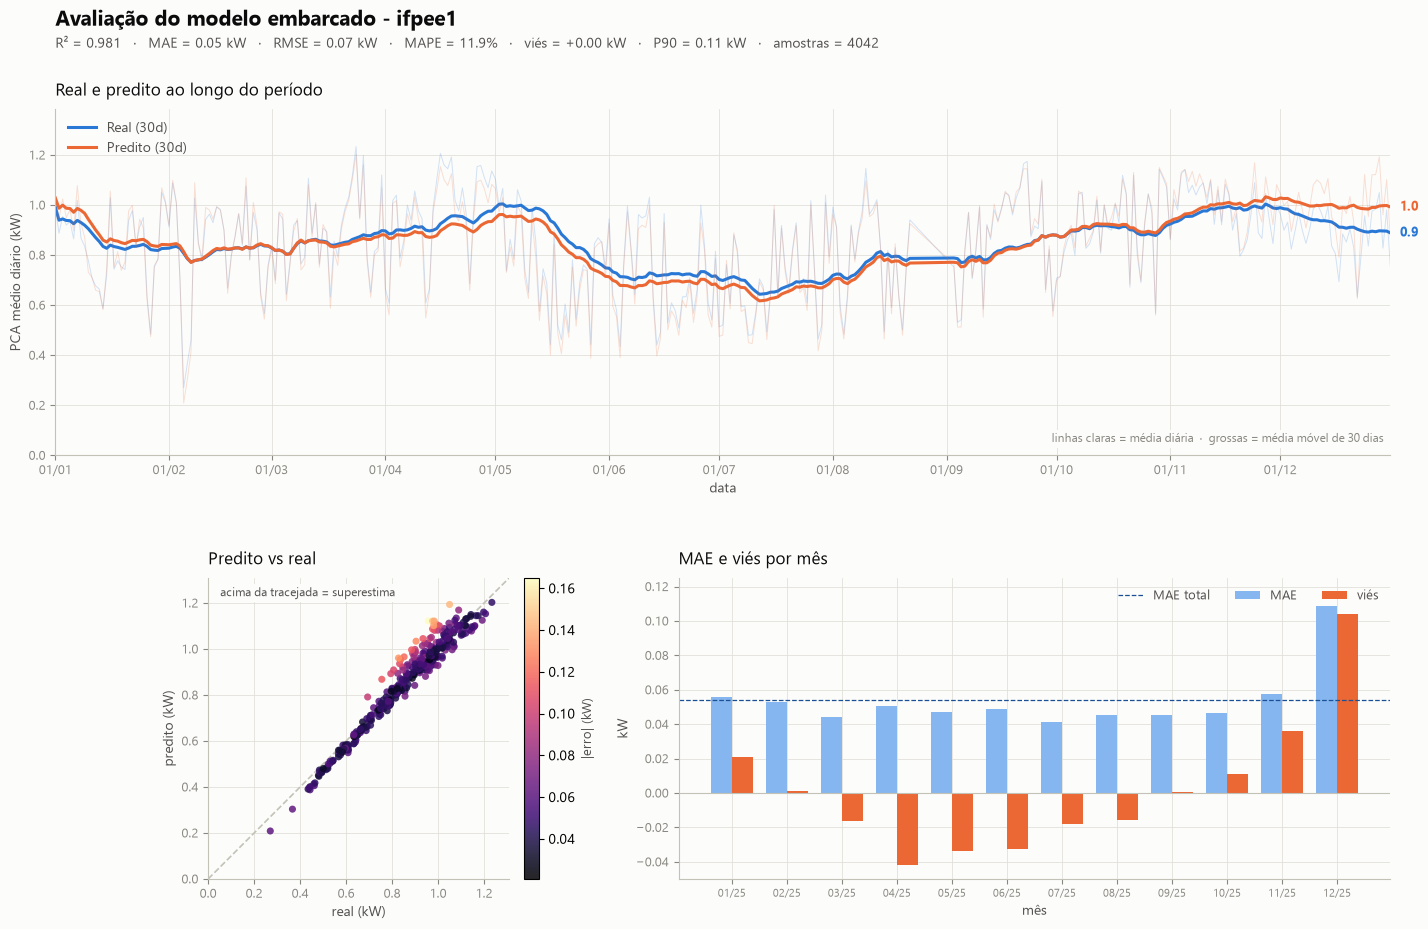

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from common import plots, server
from common.plots import (SUPERFICIE, TINTA, TINTA_2, MUDO, GRADE, EIXO,
                          REAL, PREDITO, ERRO_CLARO, MAE_ESC, HALO, enfeitar)

plots.aplicar_estilo()


def plot(df_eval: pd.DataFrame, id):
    """Painel diario de real x predito e erro absoluto.

    `df_eval` vem do log do servidor (sample, real, pred, err) ou do `reply`.
    """
    d = df_eval.copy()
    d["sample"] = pd.to_datetime(d["sample"])
    d = d.sort_values("sample").reset_index(drop=True)
    m = server.eval_metrics(d)
    r2, mae, rmse = m["r2"], m["mae"], m["rmse"]
    mape, p90, vies = m["mape"], m["p90"], m["vies"]

    # Agrega por dia: medias (funciona para log diario ou horario).
    df_dia = (d.assign(dia=d["sample"].dt.floor("D"))
               .groupby("dia", as_index=False)
               .agg(real=("real", "mean"), pred=("pred", "mean"),
                    err_abs=("err", lambda s: float(np.abs(s).mean()))))
    x1 = df_dia["dia"]
    janela = 30
    real_l = df_dia["real"].rolling(janela, min_periods=1).mean()
    pred_l = df_dia["pred"].rolling(janela, min_periods=1).mean()
    ymax = float(np.nanmax([df_dia["real"].max(), df_dia["pred"].max()])) * 1.12

    fig = plt.figure(figsize=(15, 9.5))
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.15, 1.0],
                  width_ratios=[1.0, 1.45], hspace=0.38, wspace=0.22)

    # 1. real vs predito ao longo do periodo — as duas series pelo
    # plots.plot_serie (linha crua translucida + media movel, o mesmo helper
    # dos paineis de exploracao). centro=False: media movel NAO centrada, a
    # mesma real_l/pred_l usadas na anotacao do valor final.
    ax = fig.add_subplot(gs[0, :])
    plots.plot_serie(ax, df_dia.set_index("dia")["real"], cor=REAL,
                     rotulo=f"Real ({janela}d)", janela=janela, centro=False,
                     alpha=0.20, lw=0.7, lw_media=2.2, marcador=None,
                     sombrear=False)
    plots.plot_serie(ax, df_dia.set_index("dia")["pred"], cor=PREDITO,
                     rotulo=f"Predito ({janela}d)", janela=janela, centro=False,
                     alpha=0.20, lw=0.7, lw_media=2.2, marcador=None,
                     sombrear=False)
    enfeitar(ax, "Real e predito ao longo do período", "data",
             "PCA médio diário (kW)")
    ax.set_xlim(x1.iloc[0], x1.iloc[-1])
    ax.set_ylim(0.0, ymax)
    ticks = pd.date_range(x1.iloc[0], x1.iloc[-1], freq="MS")
    ax.set_xticks(ticks)
    ax.set_xticklabels([t.strftime("%d/%m") for t in ticks])
    for serie, cor in ((real_l, REAL), (pred_l, PREDITO)):
        ax.annotate(f"{serie.iloc[-1]:.1f}", (x1.iloc[-1], serie.iloc[-1]),
                    xytext=(7, 0), textcoords="offset points", color=cor,
                    fontsize=9, va="center", fontweight="bold")
    ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2)
    ax.text(0.995, 0.03,
            f"linhas claras = média diária  ·  grossas = média móvel de {janela} dias",
            transform=ax.transAxes, ha="right", va="bottom", color=MUDO,
            fontsize=8.5, bbox=HALO)

    # 2. predito vs real, colorido pelo erro absoluto
    ax = fig.add_subplot(gs[1, 0])
    lim = (0.0, float(max(df_dia["real"].max(), df_dia["pred"].max())) * 1.06)
    ax.plot(lim, lim, color=EIXO, lw=1.2, linestyle="--", zorder=1)
    sc = ax.scatter(df_dia["real"], df_dia["pred"],
                    c=df_dia["err_abs"], cmap="magma", s=26, alpha=0.85,
                    linewidths=0, zorder=2)
    cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label("|erro| (kW)", color=TINTA_2, fontsize=9)
    ax.text(lim[1] * 0.04, lim[1] * 0.97, "acima da tracejada = superestima",
            color=TINTA_2, fontsize=8.5, va="top", bbox=HALO)
    ax.set_aspect("equal")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    enfeitar(ax, "Predito vs real", "real (kW)", "predito (kW)")

        # 3. MAE e viés por mês -- o resumo que interessa para diagnóstico
    d["abs_err"] = np.abs(d["pred"] - d["real"])
    d["signed_err"] = d["pred"] - d["real"]
    df_mes = (d.assign(mes=d["sample"].dt.to_period("M"))
               .groupby("mes", as_index=False)
               .agg(mae=("abs_err", "mean"), vies=("signed_err", "mean"),
                    n=("real", "size")))
    ax = fig.add_subplot(gs[1, 1])
    xm = np.arange(len(df_mes))
    w = 0.38
    ax.bar(xm - w / 2, df_mes["mae"], w, color=ERRO_CLARO, label="MAE")
    ax.bar(xm + w / 2, df_mes["vies"], w, color=PREDITO, label="viés")
    ax.axhline(0, color=EIXO, lw=0.8)
    ax.axhline(mae, color=MAE_ESC, lw=0.9, ls="--", label="MAE total")
    enfeitar(ax, "MAE e viés por mês", "mês", "kW")
    ax.set_xticks(xm)
    ax.set_xticklabels([m.strftime("%m/%y")
                        for m in df_mes["mes"].dt.to_timestamp()], fontsize=8)
    ymin = min(0.0, float(df_mes["vies"].min())) * 1.20
    ymax = max(mae, float(df_mes["mae"].max()), float(df_mes["vies"].max())) * 1.15
    ax.set_ylim(ymin, ymax)
    ax.legend(frameon=False, loc="upper right", fontsize=9,
              labelcolor=TINTA_2, ncol=3)

    fig.suptitle(f"Avaliação do modelo embarcado - {id}", color=TINTA,
                 fontsize=15, x=0.07, ha="left", y=0.985, fontweight="bold")
    fig.text(0.07, 0.945,
             f"R² = {r2:.3f}   ·   MAE = {mae:.2f} kW   ·   RMSE = {rmse:.2f} kW"
             f"   ·   MAPE = {mape:.1f}%   ·   viés = {vies:+.2f} kW"
             f"   ·   P90 = {p90:.2f} kW   ·   amostras = {len(d)}",
             color=TINTA_2, fontsize=10, ha="left")
    fig.subplots_adjust(top=0.88, bottom=0.07, left=0.07, right=0.96)
    plt.show()
    return fig


for inversor, df_eval in AVALIACOES.items():
    plot(df_eval.copy(), inversor)


In [18]:
import pandas as pd
from IPython.display import display

from common import server


def linha(inversor, periodo, df):
    m = server.eval_metrics(df)
    return {
        "inversor": inversor, "período": periodo, "n": m["amostras"],
        "MAE": m["mae"], "RMSE": m["rmse"], "R²": m["r2"],
        "viés": m["vies"], "MAPE (%)": m["mape"], "P90": m["p90"],
    }


linhas = []
for inversor, df in AVALIACOES.items():
    d = df.copy()
    d["sample"] = pd.to_datetime(d["sample"])
    d = d.sort_values("sample")
    linhas.append(linha(inversor, "total", d))
    for periodo, g in d.groupby(d["sample"].dt.to_period("M")):
        linhas.append(linha(inversor, str(periodo), g))

if linhas:
    tabela = pd.DataFrame(linhas).set_index(["inversor", "período"])
    display(
        tabela.style.format({
            "n": "{:d}",
            "MAE": "{:.2f}", "RMSE": "{:.2f}", "R²": "{:.3f}",
            "viés": "{:+.2f}", "MAPE (%)": "{:.1f}%", "P90": "{:.2f}",
        }).set_caption("Métricas de avaliação — log atual")
    )
else:
    print("sem avaliações para tabular")
